<a href="https://colab.research.google.com/github/Anusha161205/netflix-data-analysis/blob/main/Netflix_Content_Strategy_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Netflix Content Strategy Analysis

**Business question:** How has Netflix's catalog strategy changed between 2015 and 2021, and where is the growth coming from?

**Data:** Netflix Movies and TV Shows (`netflix_titles.csv`, Kaggle). Each row is one title. 8,807 titles added to Netflix up to 25 September 2021.

**Tools:** Python, pandas, matplotlib, seaborn

> **How to read this notebook:** it runs top to bottom. Each question has a table, a chart, a finding with numbers taken from the output, and a "So what?".
> Time trends cover 2014–2020. 2021 is excluded because the data stops on 25 September 2021, and 2014–2015 have very few titles (24 and 82), so they are treated cautiously.

## 1. Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Relative path: keep netflix_titles.csv in the same folder as this notebook
DATA_PATH = "netflix_titles.csv"

## 2. Load and inspect the raw data
Look at the data *before* changing anything, and record what you see.

In [ ]:
raw = pd.read_csv(DATA_PATH)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (8807, 12)


  show_id     type                  title         director                                                                                                                                                                                                                                                                                                             cast        country          date_added  release_year rating   duration                                                      listed_in                                                                                                                                               description
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson                                                                                                                                                                                                                                                                                                      

In [ ]:
# Missing values per column: count and percentage
missing = pd.DataFrame({
    "missing": raw.isnull().sum(),
    "pct": (raw.isnull().mean() * 100).round(1),
}).sort_values("pct", ascending=False)
missing

              missing   pct
director         2634  29.9
cast              825   9.4
country           831   9.4
date_added         10   0.1
title               0   0.0
type                0   0.0
show_id             0   0.0
release_year        0   0.0
rating              4   0.0
duration            3   0.0
listed_in           0   0.0
description         0   0.0

Duplicate rows: 0
Duplicate show_id values: 0


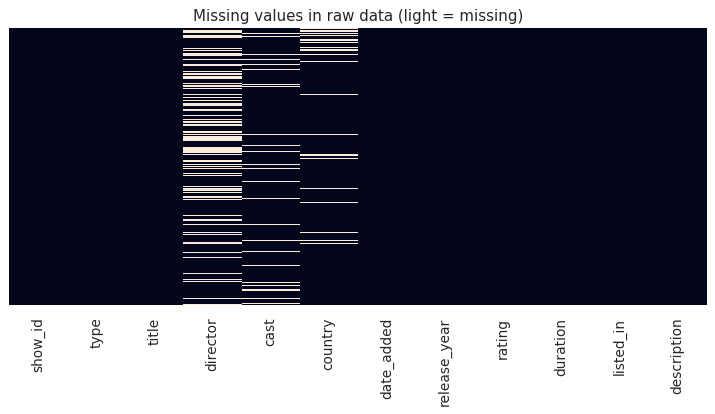

In [ ]:
# Missing-value heatmap on the RAW data (run this BEFORE any filling)
plt.figure(figsize=(10, 4))
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False)
plt.title("Missing values in raw data (light = missing)")
plt.show()

print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate show_id values:", raw["show_id"].duplicated().sum())

**Data quality notes**
- Total titles: **8,807** (12 columns).
- Columns with the most missing values: `director` (2,634, 29.9%), `country` (831, 9.4%) and `cast` (825, 9.4%). `date_added` is missing for only 10 titles (0.1%).
- Duplicates found: **0** (no duplicate rows and no duplicate `show_id`).
- `rating` is missing for 4 titles, and 3 more rows hold a duration (for example "74 min") in the rating column by mistake. All 7 are labelled "Unknown".

## 3. Cleaning
Rules followed here:
- Keep a copy of the raw data, never overwrite it.
- Do not silently drop rows. Report how many were affected and why.
- Fix multi-valued columns (`country`, `listed_in`) properly instead of treating them as one string.

In [ ]:
df = raw.copy()

# 3.1 Remove exact duplicates
before = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {before - len(df)}")

# 3.2 Parse dates. Rows with an unparseable date are kept in the dataset
#     but excluded from time-based analysis, and we report how many.
df["date_added"] = pd.to_datetime(df["date_added"].astype(str).str.strip(), errors="coerce")
n_bad_date = df["date_added"].isna().sum()
print(f"Titles with missing/invalid date_added: {n_bad_date} ({n_bad_date / len(df):.1%})")

# 3.3 Fill missing categorical values with an explicit label
for col in ["director", "cast", "country"]:
    df[col] = df[col].fillna("Unknown")

# 3.4 Rating column: a few rows contain a duration (for example '74 min') by mistake
bad_rating = df["rating"].astype(str).str.contains("min", na=False)
print(f"Rows with a duration stored in the rating column: {bad_rating.sum()}")
df.loc[bad_rating, "rating"] = np.nan
df["rating"] = df["rating"].fillna("Unknown")

# 3.5 Time features
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["added_lag_years"] = df["year_added"] - df["release_year"]   # years between release and arrival on Netflix

# 3.6 Duration: minutes for movies, number of seasons for TV shows
df["duration_num"] = pd.to_numeric(df["duration"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
df["minutes"] = np.where(df["type"] == "Movie", df["duration_num"], np.nan)
df["seasons"] = np.where(df["type"] == "TV Show", df["duration_num"], np.nan)

# 3.7 Is the last year in the data complete? Charts should not treat a partial year as a decline.
last_date = df["date_added"].max()
last_year = int(last_date.year)
print("Latest date_added:", last_date.date())
print(f"Titles added in {last_year} so far (partial year): {(df['year_added'] == last_year).sum()}")

# Dataset restricted to titles with a valid date, used for time-based questions
dated = df.dropna(subset=["date_added"]).copy()
dated["year_added"] = dated["year_added"].astype(int)
complete_years = sorted(y for y in dated["year_added"].unique() if y < last_year)

df[["title", "type", "country", "date_added", "release_year", "added_lag_years", "minutes", "seasons"]].head()

Duplicates removed: 0
Titles with missing/invalid date_added: 10 (0.1%)
Rows with a duration stored in the rating column: 3
Latest date_added: 2021-09-25
Titles added in 2021 so far (partial year): 1498


                   title     type        country date_added  release_year  added_lag_years  minutes  seasons
0   Dick Johnson Is Dead    Movie  United States 2021-09-25          2020              1.0     90.0      NaN
1          Blood & Water  TV Show   South Africa 2021-09-24          2021              0.0      NaN      2.0
2              Ganglands  TV Show        Unknown 2021-09-24          2021              0.0      NaN      1.0
3  Jailbirds New Orleans  TV Show        Unknown 2021-09-24          2021              0.0      NaN      1.0
4           Kota Factory  TV Show          India 2021-09-24          2021              0.0      NaN      2.0

In [ ]:
# Multi-valued columns -> one row per (title, country) and (title, genre)
def explode_col(frame, col):
    out = frame[["show_id", "type", "year_added", "release_year", col]].copy()
    out[col] = out[col].astype(str).str.split(",")
    out = out.explode(col)
    out[col] = out[col].str.strip()
    return out[out[col] != ""]

countries = explode_col(dated, "country").rename(columns={"country": "country_name"})
countries = countries[countries["country_name"] != "Unknown"]

genres = explode_col(dated, "listed_in").rename(columns={"listed_in": "genre"})

print("Distinct countries:", countries["country_name"].nunique())
print("Distinct genres:", genres["genre"].nunique())

Distinct countries: 122
Distinct genres: 42


**Cleaning summary**
- Removed 0 duplicates.
- 10 titles (0.1%) have no valid `date_added`: kept in the dataset, excluded from time trends.
- 9.4% of titles have an unknown country: excluded from country analysis.
- The data ends on 25 September 2021, so 2021 is a partial year (1,498 titles so far) and is excluded from year-over-year comparisons.
- Country and genre columns were split so that co-productions count once for every country and genre they involve.

## 4. Overview: what does the catalog look like?
Short and factual. The interesting questions come next.

In [ ]:
overview = df["type"].value_counts()
print(overview)
print((overview / overview.sum() * 100).round(1).astype(str) + "%")

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.6%
TV Show    30.4%
Name: count, dtype: str


## 5. Question 1: Is Netflix shifting from movies to TV shows?
Raw counts hide the trend, so compare **shares**, not totals.

type        Movie  TV Show  total  tv_share_pct
year_added                                     
2014           19        5     24          20.8
2015           56       26     82          31.7
2016          253      176    429          41.0
2017          839      349   1188          29.4
2018         1237      412   1649          25.0
2019         1424      592   2016          29.4
2020         1284      595   1879          31.7

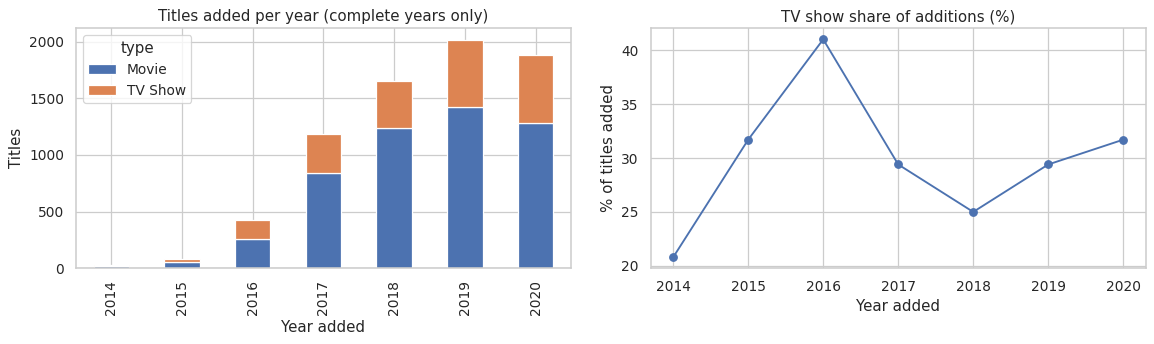

In [ ]:
by_year = (dated[dated["year_added"].isin(complete_years)]
           .groupby(["year_added", "type"]).size().unstack(fill_value=0))
by_year["total"] = by_year.sum(axis=1)
by_year["tv_share_pct"] = (by_year["TV Show"] / by_year["total"] * 100).round(1)

# Focus on the years where Netflix really scaled up
by_year = by_year[by_year.index >= 2014]
display(by_year)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_year[["Movie", "TV Show"]].plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set_title("Titles added per year (complete years only)")
ax[0].set_xlabel("Year added"); ax[0].set_ylabel("Titles")

by_year["tv_share_pct"].plot(marker="o", ax=ax[1])
ax[1].set_title("TV show share of additions (%)")
ax[1].set_xlabel("Year added"); ax[1].set_ylabel("% of titles added")
plt.tight_layout(); plt.show()

**Finding 1:** There is no steady shift from movies to TV. The TV share of additions peaked at 41.0% in 2016, fell to 25.0% in 2018 when movie additions surged (1,237 movies vs 412 TV shows), and has recovered to 31.7% in 2020. 2014 and 2015 are too small (24 and 82 titles) to read much into.

**So what?** The 2017–2018 expansion was driven mainly by movies. Since 2018, TV has grown much faster: TV additions rose 44% (412 to 595) between 2018 and 2020, while movie additions rose only 4% (1,237 to 1,284). Total additions peaked in 2019 (2,016) and dipped in 2020 (1,879).

## 6. Question 2: Is the catalog becoming more international?
Uses the exploded `country` table, so co-productions are counted for every country involved.

            non_us_share_pct
year_added                  
2014                    35.3
2015                    44.7
2016                    62.3
2017                    67.2
2018                    68.7
2019                    62.2
2020                    62.8

                before 2018 (%)  2018 onward (%)
country_name                                    
United States              36.4             35.6
United Kingdom              9.5              7.6
India                       8.2             12.0
Canada                      5.2              4.3
France                      4.4              3.7
Japan                       3.2              3.1
Spain                       2.8              2.2
South Korea                 2.5              2.3
Germany                     2.3              2.1
Mexico                      2.3              NaN
Egypt                       NaN              1.7

country_name  India  Japan  South Korea  United Kingdom  United States
year_added                                                            
2016             13     29           11              54            203
2017            162     37           43             134            462
2018            349     44           33             147            600
2019            218     74           59             191            856
2020            199     79           56             146            828

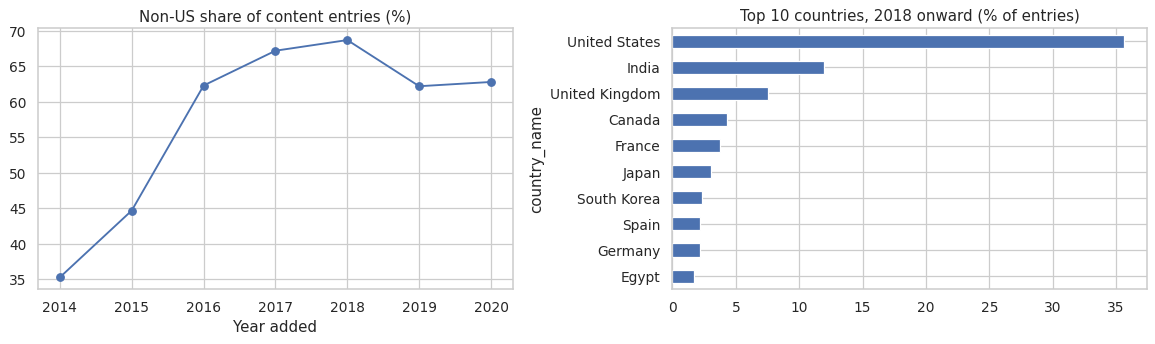

In [ ]:
c = countries[countries["year_added"].isin(complete_years)].copy()
c["is_us"] = c["country_name"] == "United States"

# Share of (title, country) entries that are non-US, per year
non_us_share = (1 - c.groupby("year_added")["is_us"].mean()) * 100
non_us_share = non_us_share[non_us_share.index >= 2014].round(1)
display(non_us_share.to_frame("non_us_share_pct"))

# Top countries: earlier period vs recent period
split_year = 2018   # splits the data into an earlier and a later period
early = c[c["year_added"] < split_year]["country_name"].value_counts(normalize=True).head(10) * 100
recent = c[c["year_added"] >= split_year]["country_name"].value_counts(normalize=True).head(10) * 100
compare = pd.concat([early.rename(f"before {split_year} (%)"),
                     recent.rename(f"{split_year} onward (%)")], axis=1).round(1)
display(compare)

# Number of title-country entries per year for the main countries
key_countries = ["United States", "India", "United Kingdom", "Japan", "South Korea"]
by_country_year = (c[c["country_name"].isin(key_countries)]
                   .groupby(["year_added", "country_name"]).size().unstack(fill_value=0))
display(by_country_year[by_country_year.index >= 2016])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
non_us_share.plot(marker="o", ax=ax[0])
ax[0].set_title("Non-US share of content entries (%)")
ax[0].set_xlabel("Year added")

(recent.sort_values().plot(kind="barh", ax=ax[1]))
ax[1].set_title(f"Top 10 countries, {split_year} onward (% of entries)")
plt.tight_layout(); plt.show()

**Finding 2:** The non-US share of content entries rose from 35.3% in 2014 to 62.3% in 2016 and 68.7% in 2018, then settled at about 62–63% in 2019–2020. Most of the internationalization happened by 2017. Comparing before and after 2018, the US share is almost unchanged (36.4% to 35.6%), the UK fell (9.5% to 7.6%), and India rose (8.2% to 12.0%). India's entries peaked at 349 in 2018 and were 199 in 2020, so its higher share is a step up rather than continued growth.

**So what?** The big move away from US-only content was a 2015–2017 story. Since then the mix has been stable, with India as the largest non-US source since 2018 (12.0% of entries vs 7.6% for the UK).

## 7. Question 3: How old is content when Netflix adds it?
`added_lag_years = year_added - release_year`. A shrinking lag suggests a move from licensed library content to new releases and originals.

            median  pct_same_or_prev_year  pct_5plus_years_old
year_added                                                    
2014           0.0                   83.3                 12.5
2015           0.0                   81.7                  9.8
2016           1.0                   65.3                 19.0
2017           1.0                   59.7                 17.0
2018           1.0                   54.7                 26.4
2019           1.0                   51.5                 29.7
2020           1.0                   55.4                 28.0

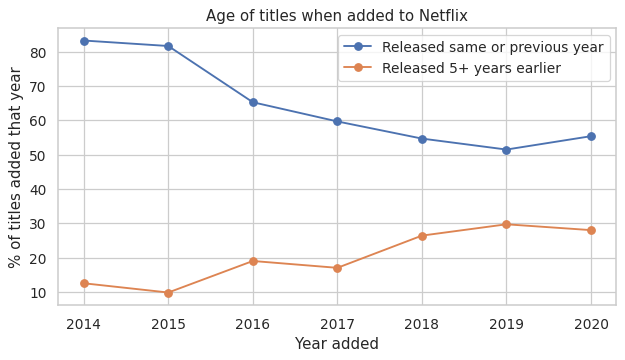

In [ ]:
lag = dated[(dated["year_added"].isin(complete_years)) & (dated["added_lag_years"] >= 0)]
lag_summary = (lag.groupby("year_added")["added_lag_years"]
                  .agg(median="median",
                       pct_same_or_prev_year=lambda s: (s <= 1).mean() * 100,
                       pct_5plus_years_old=lambda s: (s >= 5).mean() * 100)
                  .round(1))
lag_summary = lag_summary[lag_summary.index >= 2014]
display(lag_summary)

lag_summary[["pct_same_or_prev_year", "pct_5plus_years_old"]].plot(marker="o", figsize=(8, 4))
plt.title("Age of titles when added to Netflix")
plt.xlabel("Year added"); plt.ylabel("% of titles added that year")
plt.legend(["Released same or previous year", "Released 5+ years earlier"])
plt.show()

**Finding 3:** Netflix has been adding older titles over time. The share of additions released in the same or previous year fell from 81.7% in 2015 to 51.5% in 2019 (55.4% in 2020). The share released 5 or more years earlier rose from 9.8% in 2015 to 29.7% in 2019 (28.0% in 2020). The median age is only 0 to 1 year because most titles are recent, so these percentages show the change better than the median does.

**So what?** Alongside the jump in volume (82 titles in 2015 to 2,016 in 2019), this suggests growth after 2016 came partly from backfilling the catalog with older titles, likely licensed library content rather than only new releases. The data has no Original vs licensed flag, so this is an inference from release year.

## 8. Question 4: Who is the content made for? (ratings)

type    Movie  TV Show
rating                
TV-MA    33.6     42.9
TV-14    23.3     27.4
R        13.0      0.1
TV-PG     8.8     12.0
PG-13     8.0      0.0
PG        4.7      0.0
TV-Y7     2.3      7.3
TV-Y      2.1      6.6
TV-G      2.1      3.5
NR        1.2      0.2

Adult-rated share of all titles: 45.5%


            adult_rated_pct
year_added                 
2016                   41.3
2017                   43.2
2018                   47.2
2019                   46.9
2020                   45.7

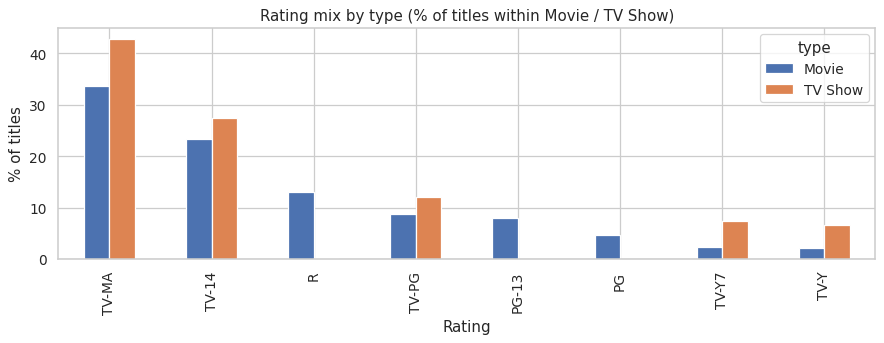

In [ ]:
rating_share = (pd.crosstab(dated["rating"], dated["type"], normalize="columns") * 100).round(1)
rating_share = rating_share.sort_values("Movie", ascending=False)
display(rating_share.head(10))

# Share of adult-rated titles (TV-MA, R, NC-17) overall and by year added
adult = {"TV-MA", "R", "NC-17"}
print(f"Adult-rated share of all titles: {dated['rating'].isin(adult).mean() * 100:.1f}%")
adult_by_year = (dated[dated["year_added"].isin(complete_years) & (dated["year_added"] >= 2016)]
                 .groupby("year_added")["rating"].apply(lambda s: round(s.isin(adult).mean() * 100, 1)))
display(adult_by_year.to_frame("adult_rated_pct"))

rating_share.head(8).plot(kind="bar", figsize=(10, 4))
plt.title("Rating mix by type (% of titles within Movie / TV Show)")
plt.ylabel("% of titles"); plt.xlabel("Rating")
plt.tight_layout(); plt.show()

**Finding 4:** Adult-rated titles (TV-MA, R, NC-17) make up 45.5% of the catalog, and their share of yearly additions rose from 41.3% in 2016 to 47.2% in 2018 and 45.7% in 2020. TV-MA covers 42.9% of TV shows and 33.6% of movies (plus another 13.0% of movies rated R). TV also has more children's content: TV-Y, TV-Y7 and TV-G together are 17.4% of TV shows versus 6.5% of movies. Movies and TV use different rating systems, so compare the two with care.

## 9. Question 5: Duration patterns
Use the **median** for duration because a few very long or very short titles distort the mean.

            median  count
year_added               
2014          78.0     19
2015          82.0     56
2016          88.0    251
2017          94.0    838
2018         100.0   1237
2019          99.0   1424
2020         101.0   1284

         pct_of_tv_shows
seasons                 
1.0                 67.3
2.0                 15.8
3.0                  7.4
4.0                  3.5
5.0                  2.4
6.0                  1.2
7.0                  0.9
8.0                  0.6

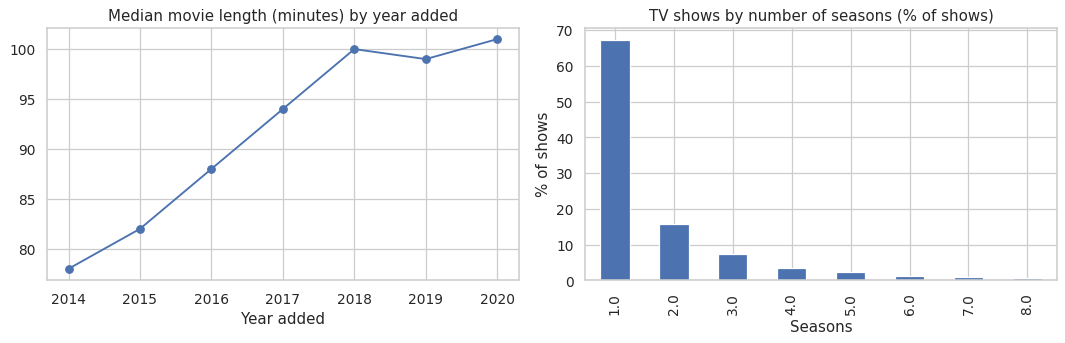

In [ ]:
movies = dated[(dated["type"] == "Movie") & (dated["year_added"].isin(complete_years))]
movie_len = movies.groupby("year_added")["minutes"].agg(["median", "count"])
movie_len = movie_len[movie_len.index >= 2014]
display(movie_len)

shows = dated[dated["type"] == "TV Show"]
season_dist = (shows["seasons"].value_counts(normalize=True).sort_index() * 100).round(1)
display(season_dist.head(8).to_frame("pct_of_tv_shows"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
movie_len["median"].plot(marker="o", ax=ax[0])
ax[0].set_title("Median movie length (minutes) by year added")
ax[0].set_xlabel("Year added")

season_dist.head(8).plot(kind="bar", ax=ax[1])
ax[1].set_title("TV shows by number of seasons (% of shows)")
ax[1].set_xlabel("Seasons"); ax[1].set_ylabel("% of shows")
plt.tight_layout(); plt.show()

**Finding 5:** 67.3% of TV shows have only one season, 15.8% have two and 7.4% have three, so the share keeps falling with each extra season. The data cannot tell limited series, cancellations and recent shows apart, so this is a pattern rather than an explanation. The median movie length rose from 78 minutes in 2014 (19 movies) to about 100 minutes from 2018 onward (more than 1,200 movies a year), and has been steady at 99–101 minutes since 2018.

## 10. Question 6: Is there a seasonal pattern in additions?
Compare each month's *share of its year's additions*, so busy years do not dominate.

             avg_pct_of_yearly_additions
month_added                             
1                                    8.1
2                                    6.4
3                                    9.2
4                                    8.1
5                                    7.1
6                                    7.3
7                                    7.9
8                                    8.2
9                                    8.0
10                                  10.2
11                                   9.3
12                                  10.2

Busiest month per year (1 = January): {2017: 10, 2018: 10, 2019: 11, 2020: 1}


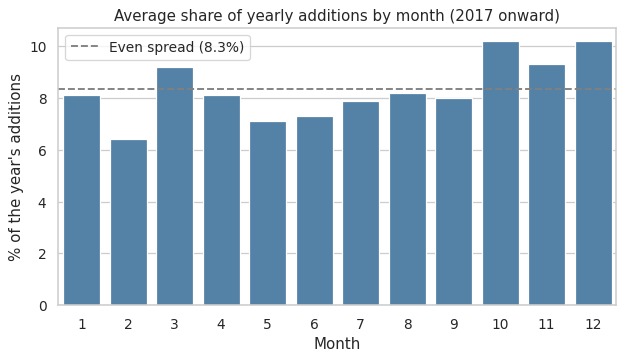

In [ ]:
# Start in 2017: 2016 was a small year (429 titles) with an unusually large December
m = dated[dated["year_added"].isin(complete_years) & (dated["year_added"] >= 2017)].copy()
m["month_added"] = m["month_added"].astype(int)
monthly = m.groupby(["year_added", "month_added"]).size().unstack(fill_value=0)
monthly_share = monthly.div(monthly.sum(axis=1), axis=0) * 100
avg_share = monthly_share.mean().round(1)
display(avg_share.to_frame("avg_pct_of_yearly_additions"))

# Which month was the busiest in each year? (is the pattern consistent?)
print("Busiest month per year (1 = January):", monthly_share.idxmax(axis=1).to_dict())

plt.figure(figsize=(8, 4))
sns.barplot(x=avg_share.index, y=avg_share.values, color="steelblue")
plt.axhline(100 / 12, color="gray", linestyle="--", label="Even spread (8.3%)")
plt.title("Average share of yearly additions by month (2017 onward)")
plt.xlabel("Month"); plt.ylabel("% of the year's additions"); plt.legend()
plt.show()

**Finding 6:** Seasonality is weak. From 2017 onward, October and December each average 10.2% of a year's additions (versus 8.3% if spread evenly), and February is the lowest at 6.4%. The busiest month changes from year to year (October in 2017 and 2018, November in 2019, January in 2020), so there is no reliable seasonal pattern. 2016 is excluded because December alone held 22.4% of that year's titles.

## 11. Question 7: Does each country specialize in different genres?

genre           International Movies  Dramas  Comedies  International TV Shows  Action & Adventure  Documentaries  Independent Movies  Thrillers  TV Dramas  Children & Family Movies
country                                                                                                                                                                              
Canada                           6.8     9.4      10.7                     2.9                 5.0            4.8                 5.0        5.6        3.6                       9.1
France                          22.6    18.2       5.6                     4.7                 4.0            4.8                 8.0        4.8        2.9                       2.5
India                           30.8    23.6      11.5                     2.4                 4.9            1.0                 6.0        3.3        1.0                       0.9
Japan                            9.8     3.1       1.2                    20.7            

                tv_share_pct
country_name                
India                    8.0
Germany                 19.5
France                  22.9
United States           25.3
Spain                   26.3
Canada                  28.3
United Kingdom          33.7
Japan                   62.5
South Korea             73.6

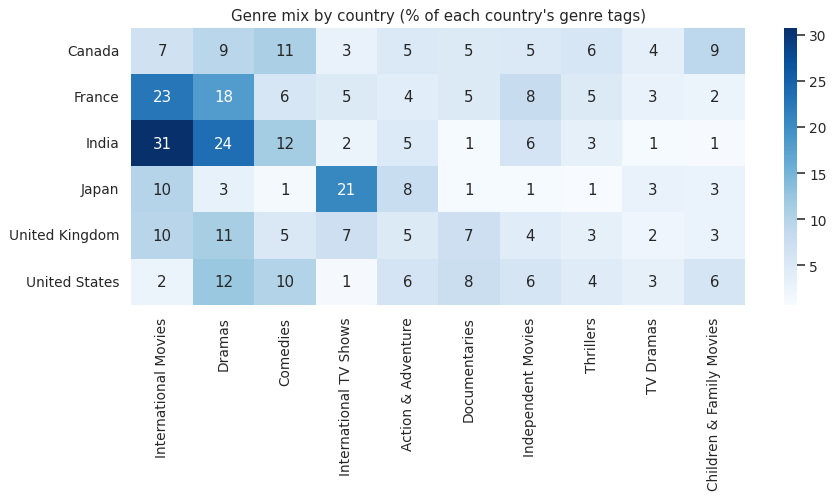

In [ ]:
cg = (dated[["show_id", "country"]]
      .assign(country=lambda d: d["country"].str.split(","))
      .explode("country"))
cg["country"] = cg["country"].str.strip()
cg = cg[~cg["country"].isin(["Unknown", ""])]
cg = cg.merge(genres[["show_id", "genre"]], on="show_id")

top_countries = cg["country"].value_counts().head(6).index
top_genres = cg["genre"].value_counts().head(10).index

genre_mix = (pd.crosstab(cg[cg["country"].isin(top_countries)]["country"],
                         cg[cg["country"].isin(top_countries)]["genre"],
                         normalize="index")[top_genres] * 100).round(1)
display(genre_mix)

# Movie vs TV mix per country (countries with at least 200 entries)
big = countries["country_name"].value_counts()
big = big[big >= 200].index
country_type = (countries[countries["country_name"].isin(big)]
                .groupby("country_name")["type"]
                .apply(lambda s: round((s == "TV Show").mean() * 100, 1))
                .sort_values())
display(country_type.to_frame("tv_share_pct"))

plt.figure(figsize=(11, 4))
sns.heatmap(genre_mix, annot=True, fmt=".0f", cmap="Blues")
plt.title("Genre mix by country (% of each country's genre tags)")
plt.xlabel(""); plt.ylabel("")
plt.show()

**Finding 7:** Countries differ sharply in format. Only 8.0% of India's titles are TV shows, compared with 25.3% for the US and 33.7% for the UK, while Japan (62.5%) and South Korea (73.6%) are mostly TV. India's catalog is also concentrated in International Movies (30.8% of its genre tags) and Dramas (23.6%). The "International" tags are applied to non-US content, so the high International Movies share for India is expected on its own.

## 12. Conclusions and recommendation

**Top findings**
1. **Growth came with older content.** Yearly additions rose from 82 (2015) to 2,016 (2019), and the share of additions that were 5+ years old rose from 9.8% to 29.7%.
2. **Internationalization happened early and then levelled off.** The non-US share of entries went from 35.3% (2014) to 68.7% (2018), then held at about 62–63%. India is the main gainer since 2018 (8.2% to 12.0% of entries).
3. **India's catalog is almost all movies.** Only 8.0% of India's titles are TV shows, versus 62.5% for Japan and 73.6% for South Korea.
4. **TV is growing back.** TV share fell from 41.0% (2016) to 25.0% (2018) and reached 31.7% in 2020. TV additions grew 44% from 2018 to 2020, versus 4% for movies.

**Recommendation**
> India has been Netflix's largest non-US source of content since 2018 (12.0% of entries), but only 8.0% of its titles are TV shows, while TV dominates the Korean and Japanese catalogs. A content-acquisition team should investigate Indian TV series as the biggest gap in the international catalog, for example by comparing viewing of existing Indian series with Indian movies.

**Limitations**
- The data has no viewership numbers. Counts show what Netflix *carries*, not what people *watch*.
- The dataset ends on 25 September 2021, so recent trends are not captured, and 2014–2015 have too few titles for firm conclusions.
- There is no Original vs licensed flag, so statements about older or library content are inferred from release year.
- Every title counts equally, whether it is a blockbuster or an obscure documentary.
- `country` lists production countries, which is not the same as the language or audience of the title.



## 13. Optional: the same analysis in SQL


In [ ]:
import sqlite3

conn = sqlite3.connect(":memory:")
export = dated[["show_id", "type", "title", "release_year", "year_added", "month_added", "rating"]]
export.to_sql("titles", conn, index=False, if_exists="replace")

query = '''
WITH yearly AS (
    SELECT year_added,
           COUNT(*) AS total,
           SUM(CASE WHEN type = 'TV Show' THEN 1 ELSE 0 END) AS tv_shows
    FROM titles
    WHERE year_added < (SELECT MAX(year_added) FROM titles)
      AND year_added >= 2014
    GROUP BY year_added
)
SELECT year_added,
       total,
       ROUND(100.0 * tv_shows / total, 1) AS tv_share_pct,
       ROUND(100.0 * tv_shows / total
             - LAG(100.0 * tv_shows / total) OVER (ORDER BY year_added), 1) AS change_vs_prev_year
FROM yearly
ORDER BY year_added;
'''
pd.read_sql(query, conn)

   year_added  total  tv_share_pct  change_vs_prev_year
0        2014     24          20.8                  NaN
1        2015     82          31.7                 10.9
2        2016    429          41.0                  9.3
3        2017   1188          29.4                -11.6
4        2018   1649          25.0                 -4.4
5        2019   2016          29.4                  4.4
6        2020   1879          31.7                  2.3